In [ ]:
%load_ext autoreload
%autoreload 2

import warnings
import urllib.request
from pathlib import Path


import torch
import pandas as pd

from src.data_process import load_data_from_df
from src.utils import create_dir_if_not_exists
from src.experiments.experiment import (
    rf_experiment,
    mat_tt_experiment,
    mat_lr_experiment,
    mat_dense_experiment,
    mat_pruned_experiment,
)
from src.report import (
    prep_visual,
    prepare_history,
    get_metrics_mat_lr,
    get_metrics_mat_tt,
    plot_compression_bar,
    plot_training_history,
    get_metrics_baselines, 
    get_metrics_mat_pruned,
    prepare_ablations_table,
    prepare_best_results_table,
)

from configs.mat_lr import RANK_OPTIONS
from configs.mat_tt import RANK_C_OPTIONS
from configs.mat_pruned import PRUNE_OPTIONS
from configs.shared import TARGET_LAYERS_FS, TARGET_LAYERS_FT

warnings.filterwarnings("ignore")


DATA_DIR = Path('./data/esol/')
DATA_PATH = str(DATA_DIR / "esol.csv")
ART_DIR = Path('./artifacts/training_artifacts')
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load and Prepare the ESOL Dataset:

In [ ]:
url = (
    "https://raw.githubusercontent.com/ardigen/MAT/refs/" 
    + "heads/master/data/esol/esol.csv"
)
DATA_DIR.mkdir(parents=True, exist_ok=True)
urllib.request.urlretrieve(url, filename=DATA_DIR / 'esol.csv')
print(f'ESOL Dataset downloaded ✅')

ESOL Dataset downloaded ✅


In [ ]:
%%capture
load_data_from_df(DATA_PATH, fingerprints=True);
load_data_from_df(DATA_PATH, fingerprints=False);

## Training Models and Gathering Statistics:

- Takes about 60 minutes on GPU - GeForce RTX 3060;
- Takes about 200 minutes on CPU - Intel Core I7-1365U;

In [2]:
# Random Forest model:
rf_experiment(ART_DIR, DATA_PATH)
# MAT-Dense model:
mat_dense_experiment(ART_DIR, DATA_PATH, DEVICE)
# MAT-Pruned model:
mat_pruned_experiment(
    ART_DIR, DATA_PATH, DEVICE, TARGET_LAYERS_FT, PRUNE_OPTIONS
)
# MAT-TT trained from scratch (FS):
mat_tt_experiment(
    ART_DIR, DATA_PATH, DEVICE, "FS", TARGET_LAYERS_FS, RANK_C_OPTIONS, 
)
# MAT-TT fine-tuned (FT):
mat_tt_experiment(
    ART_DIR, DATA_PATH, DEVICE, "FT", TARGET_LAYERS_FT, RANK_C_OPTIONS, 
)
# MAT-LR trained from scratch (FS):
mat_lr_experiment(
    ART_DIR, DATA_PATH, DEVICE, "FS", TARGET_LAYERS_FS, RANK_OPTIONS,
)
# MAT-LR fine-tuned (FT):
mat_lr_experiment(
    ART_DIR, DATA_PATH, DEVICE, "FT", TARGET_LAYERS_FT, RANK_OPTIONS,
)

Running Random Forest


100%|██████████| 3/3 [00:20<00:00,  6.82s/it]


Running MAT-Dense


100%|██████████| 3/3 [02:18<00:00, 46.32s/it]


Running MAT-Pruned: |layer=self_attn|amount=0.7


100%|██████████| 3/3 [02:08<00:00, 42.97s/it]


... (42 outputs left out)

Running MAT-LR: mode=FT|layer=feed_forward|rank=2


100%|██████████| 3/3 [02:06<00:00, 42.03s/it]


Running MAT-LR: mode=FT|layer=feed_forward|rank=4


100%|██████████| 3/3 [02:06<00:00, 42.19s/it]


## Results and Analysis:

### Best Results Table:

- 3 random seeds were used;
- Training Compressed Models: **FT** = Fine-Tuning; **FS** = From Scratch;
- Compressed Layers: **Attn** = Attention; **FF** = Feed Forward; **Emb** = Embedding;
- Compression Methods: **TT** = Tensor Train; **LR** = Low-Rank (matrices); **Pruned** = Zeroing out by L1-norm;
- Baselines: **RF** = Random Forest (fingerprints data); **MAT-Dense** = Full Model;

In [2]:
prepare_best_results_table(ART_DIR)

,Method,Configuration,Test RMSE ↓,Train Time ↓,Parameters ↓,Compression Ratio ↑
0,RF,-,0.533 ± 0.036,1.0 ± 1.1,-,-
1,MAT-Dense,-,0.310 ± 0.042,46.0 ± 1.0,"203,009",1.00×
1,MAT-Pruned,"FT, Attn, 50%",0.303 ± 0.042,38.6 ± 9.3,"203,009",1.00×
3,MAT-LR,"FS, Attn, rank 4",0.302 ± 0.041,47.4 ± 1.0,"80,129",2.53×
4,MAT-TT,"FS, FF, rank 2",0.314 ± 0.028,58.7 ± 0.7,"138,049",1.47×


### Compression Ablations:

In [3]:
save_path  = Path(f'./artifacts/results')
create_dir_if_not_exists(save_path)

bl_df = get_metrics_baselines(ART_DIR)
dense_rmse, dense_std = (
    bl_df[bl_df['model'] == 'MAT-Dense']
    .iloc[0][["test_rmse_m", "test_rmse_s"]]
    .values
)

#### Tensor Train (TT):

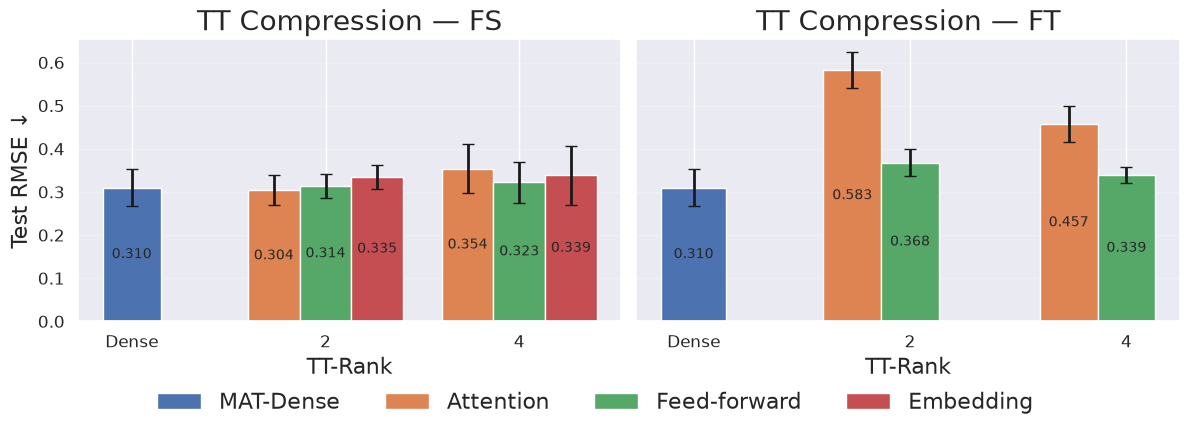

,Method,Configuration,Test RMSE ↓,Validation RMSE ↓,Train Time ↓,Parameters (Total) ↓,Parameters (Trainable) ↓,Compression Ratio ↑
1,MAT-Dense,-,0.310 ± 0.042,0.293 ± 0.040,46.0 ± 1.0,"203,009","203,009",1.00×
0,MAT-TT,"FS, Emb, rank 2",0.335 ± 0.028,0.327 ± 0.043,48.7 ± 0.6,"199,833","199,833",1.02×
1,MAT-TT,"FS, Emb, rank 4",0.339 ± 0.069,0.319 ± 0.035,48.8 ± 0.6,"200,065","200,065",1.01×
2,MAT-TT,"FS, Attn, rank 2",0.304 ± 0.034,0.329 ± 0.053,70.7 ± 0.5,"73,089","73,089",2.78×
3,MAT-TT,"FS, Attn, rank 4",0.354 ± 0.057,0.346 ± 0.036,70.6 ± 0.9,"75,521","75,521",2.69×
4,MAT-TT,"FS, FF, rank 2",0.314 ± 0.028,0.307 ± 0.037,58.7 ± 0.7,"138,049","138,049",1.47×
5,MAT-TT,"FS, FF, rank 4",0.323 ± 0.047,0.316 ± 0.032,55.8 ± 4.7,"139,265","139,265",1.46×
6,MAT-TT,"FT, Attn, rank 2",0.583 ± 0.041,0.637 ± 0.053,67.9 ± 0.8,"73,089","2,176",2.78×
7,MAT-TT,"FT, Attn, rank 4",0.457 ± 0.043,0.508 ± 0.036,68.0 ± 1.1,"75,521","4,608",2.69×
8,MAT-TT,"FT, FF, rank 2",0.368 ± 0.032,0.390 ± 0.035,54.0 ± 0.8,"138,049","1,088",1.47×


In [4]:
tt_df = get_metrics_mat_tt(RANK_C_OPTIONS, ART_DIR)

plot_compression_bar(
    prep_visual(tt_df),
    x_col="rank",
    group_col="layer",
    style_col="mode",
    style_order=["FS", "FT"],
    group_order=["Attention", "Feed-forward", "Embedding"],
    title="TT Compression",
    x_label="TT-Rank",
    y_label="Test RMSE ↓",
    reference_rmse=dense_rmse,
    reference_std=dense_std,
    figsize=(6, 4),
    save_path=str(save_path / 'mat_tt_ablation.png'),
)

prepare_ablations_table(
    pd.concat([bl_df[bl_df['model'] == 'MAT-Dense'], tt_df])
)

##### How does compression affect optimization?

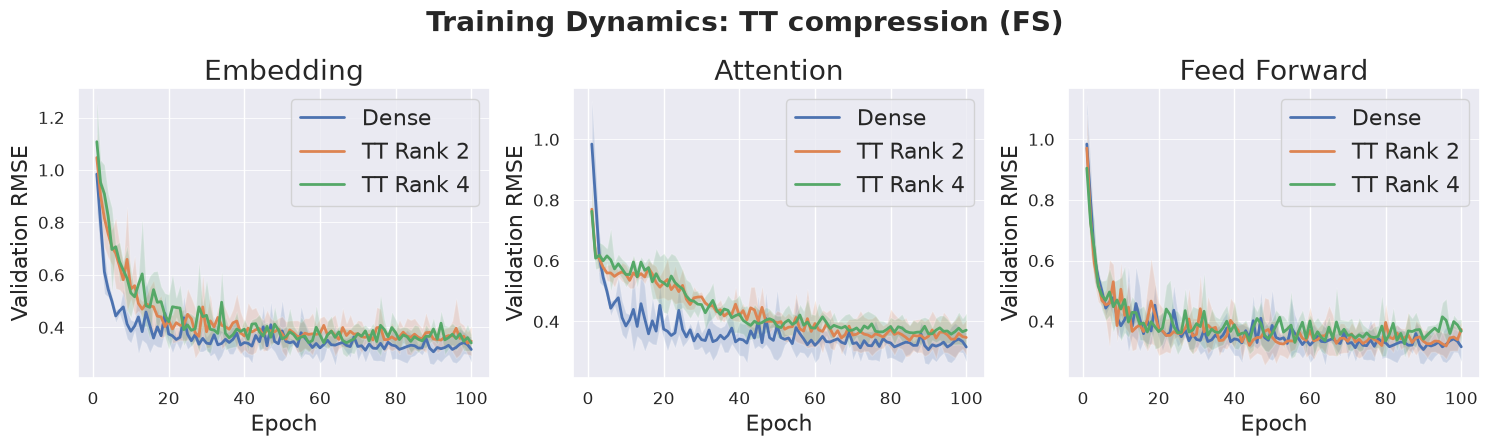

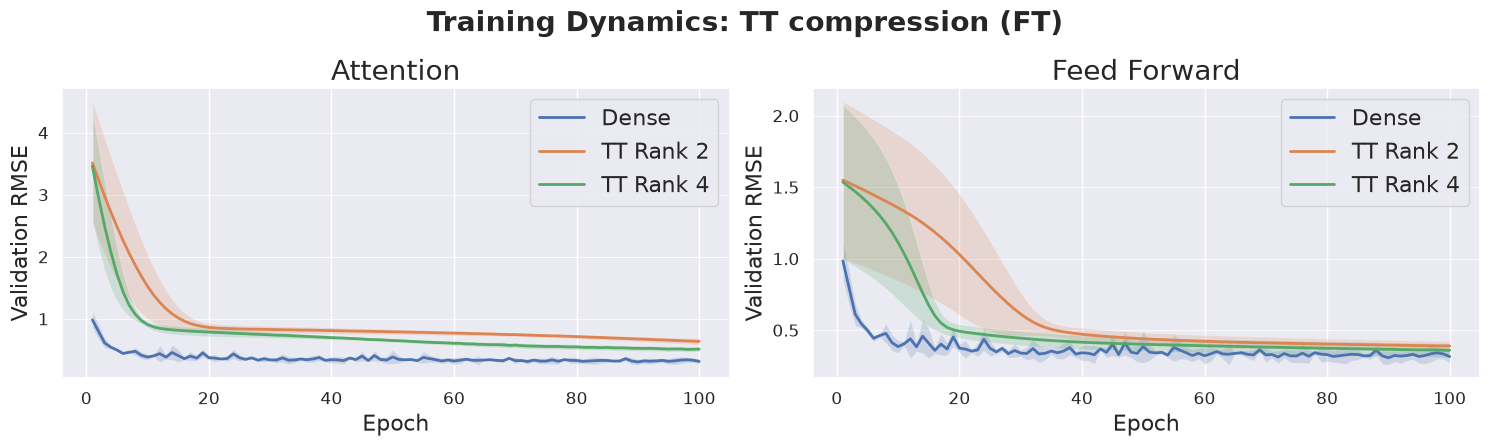

In [5]:
for mode in ("FS", "FT"):
    plot_training_history(
        prepare_history("TT", mode, ART_DIR),
        title=f"Training Dynamics: TT compression ({mode})",
        save_path=str(save_path / f'mat_tt_dynamics_{mode.lower()}.png'),
    )

#### Low-Rank (LR):

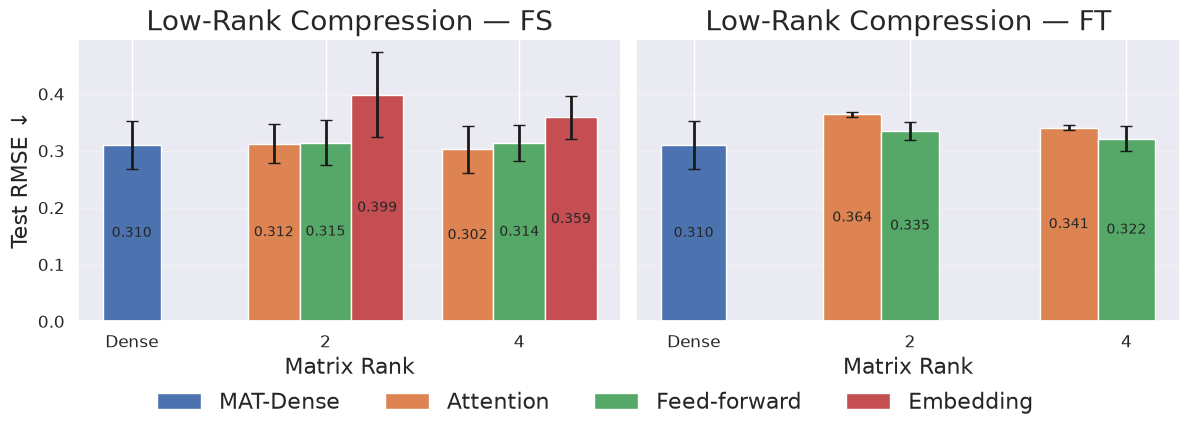

,Method,Configuration,Test RMSE ↓,Validation RMSE ↓,Train Time ↓,Parameters (Total) ↓,Parameters (Trainable) ↓,Compression Ratio ↑
1,MAT-Dense,-,0.310 ± 0.042,0.293 ± 0.040,46.0 ± 1.0,"203,009","203,009",1.00×
0,MAT-LR,"FS, Emb, rank 2",0.399 ± 0.075,0.381 ± 0.034,46.3 ± 0.7,"199,989","199,989",1.02×
1,MAT-LR,"FS, Emb, rank 4",0.359 ± 0.038,0.341 ± 0.052,46.4 ± 0.7,"200,297","200,297",1.01×
2,MAT-LR,"FS, Attn, rank 2",0.312 ± 0.034,0.305 ± 0.015,46.9 ± 0.6,"76,033","76,033",2.67×
3,MAT-LR,"FS, Attn, rank 4",0.302 ± 0.041,0.301 ± 0.042,47.4 ± 1.0,"80,129","80,129",2.53×
4,MAT-LR,"FS, FF, rank 2",0.315 ± 0.040,0.315 ± 0.048,45.6 ± 2.4,"139,521","139,521",1.46×
5,MAT-LR,"FS, FF, rank 4",0.314 ± 0.032,0.308 ± 0.050,46.0 ± 1.0,"141,569","141,569",1.43×
6,MAT-LR,"FT, Attn, rank 2",0.364 ± 0.004,0.403 ± 0.062,45.0 ± 0.8,"76,033","5,120",2.67×
7,MAT-LR,"FT, Attn, rank 4",0.341 ± 0.005,0.360 ± 0.031,45.6 ± 0.5,"80,129","9,216",2.53×
8,MAT-LR,"FT, FF, rank 2",0.335 ± 0.016,0.339 ± 0.039,42.0 ± 0.8,"139,521","2,560",1.46×


In [6]:
lr_df = get_metrics_mat_lr(RANK_OPTIONS, ART_DIR)

plot_compression_bar(
    prep_visual(lr_df),
    x_col="rank",
    group_col="layer",
    style_col="mode",
    style_order=["FS", "FT"],
    group_order=["Attention", "Feed-forward", "Embedding"],
    title="Low-Rank Compression",
    x_label="Matrix Rank",
    y_label="Test RMSE ↓",
    reference_rmse=dense_rmse,
    reference_std=dense_std,
    figsize=(6, 4),
    save_path=str(save_path / 'mat_lr_ablation.png'),
)

prepare_ablations_table(
    pd.concat([bl_df[bl_df['model'] == 'MAT-Dense'], lr_df])
)

##### How does compression affect optimization?

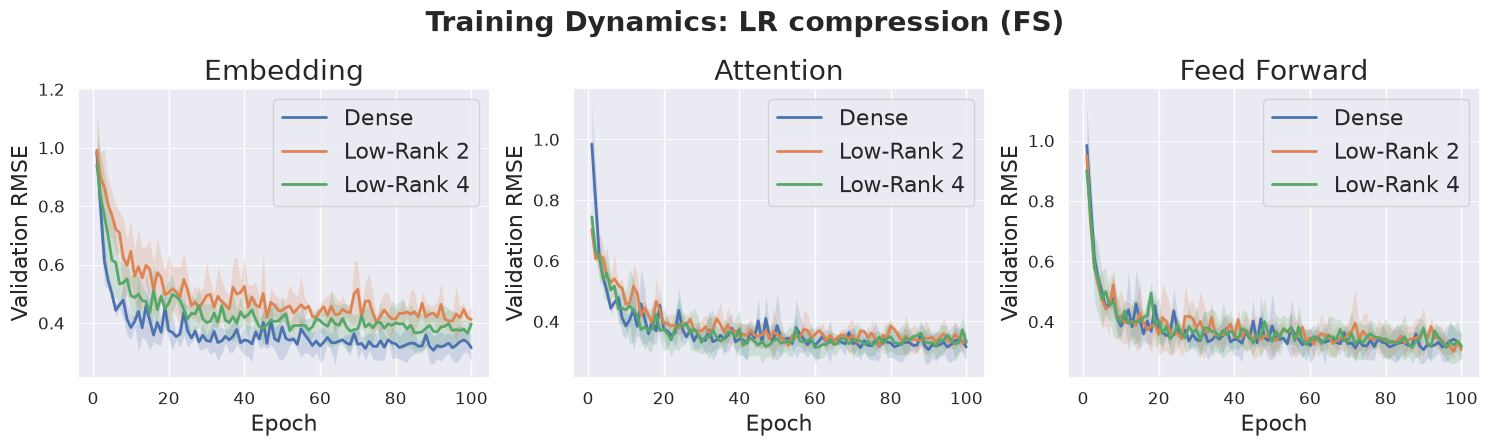

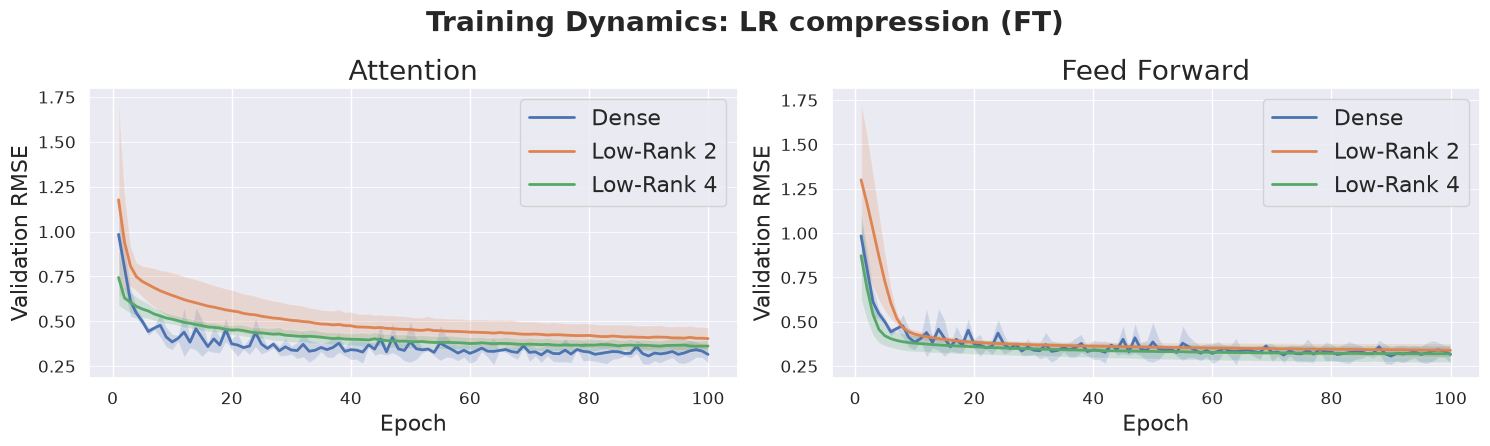

In [7]:
for mode in ("FS", "FT"):
    plot_training_history(
        prepare_history("LR", mode, ART_DIR),
        title=f"Training Dynamics: LR compression ({mode})",
        save_path=str(save_path / f'mat_lr_dynamics_{mode.lower()}.png'),
    )

#### Pruning:

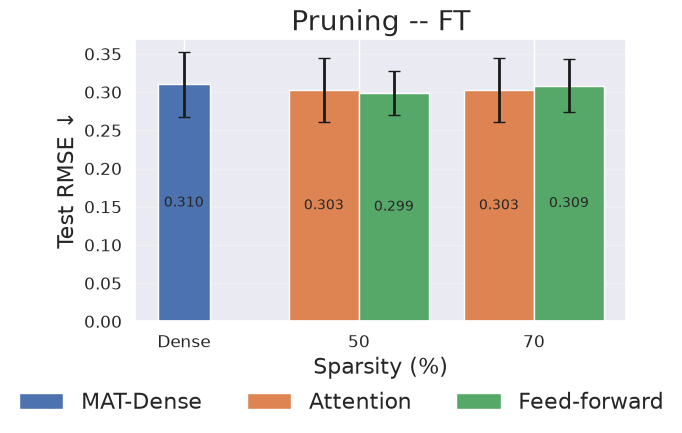

,Method,Configuration,Test RMSE ↓,Validation RMSE ↓,Train Time ↓,Parameters (Total) ↓,Parameters (Trainable) ↓,Compression Ratio ↑,Parameters (Nonzero) ↓
1,MAT-Dense,-,0.310 ± 0.042,0.293 ± 0.040,46.0 ± 1.0,"203,009","203,009",1.00×,"203,009"
0,MAT-Pruned,"FT, Attn, 70%",0.303 ± 0.042,0.295 ± 0.039,42.9 ± 2.4,"203,009","132,096",1.00×,"111,259"
1,MAT-Pruned,"FT, Attn, 50%",0.303 ± 0.042,0.292 ± 0.034,38.6 ± 9.3,"203,009","132,096",1.00×,"137,473"
2,MAT-Pruned,"FT, FF, 70%",0.309 ± 0.034,0.308 ± 0.038,41.6 ± 1.1,"203,009","66,048",1.00×,"157,134"
3,MAT-Pruned,"FT, FF, 50%",0.299 ± 0.029,0.297 ± 0.039,25.8 ± 0.2,"203,009","66,048",1.00×,"170,241"


In [8]:
pruned_df = get_metrics_mat_pruned(TARGET_LAYERS_FT, PRUNE_OPTIONS, ART_DIR)

plot_compression_bar(
    prep_visual(pruned_df, prune_bool=True),
    x_col="sparsity",
    group_col="layer",
    title="Pruning -- FT",
    x_label="Sparsity (%)",
    y_label="Test RMSE ↓",
    reference_rmse=dense_rmse,
    reference_std=dense_std,
    figsize=(6, 4),
    save_path=str(save_path / 'mat_pruned_ablation.png'),
)

prepare_ablations_table(
    pd.concat([bl_df[bl_df['model'] == 'MAT-Dense'], pruned_df]),
    non_zero=True,
)

##### How does compression affect optimization?

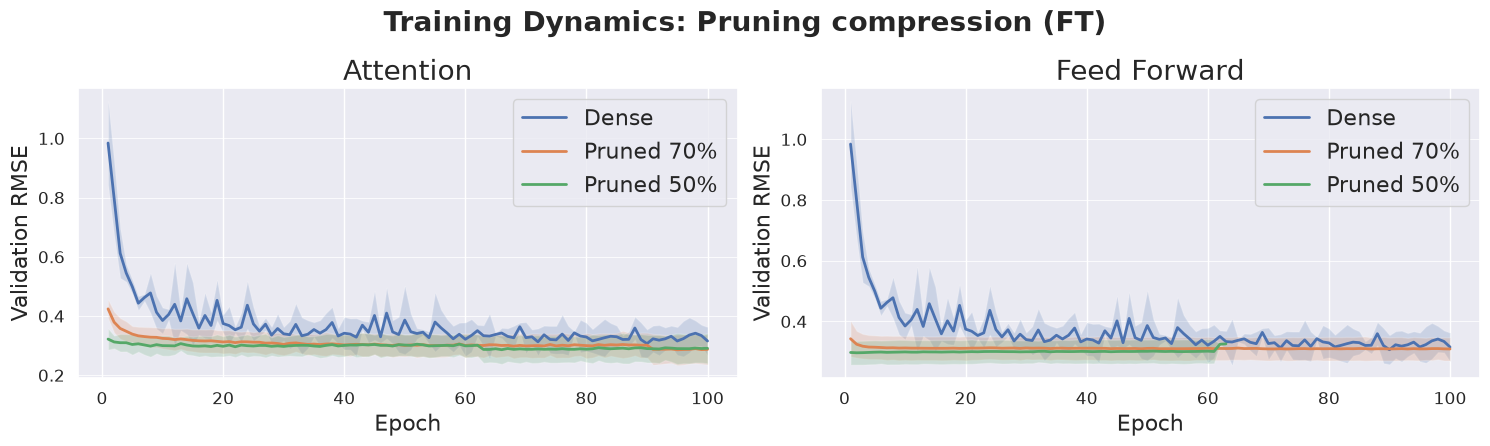

In [9]:
for mode in ("FT",):
    plot_training_history(
        prepare_history("Pruned", mode, ART_DIR),
        title=f"Training Dynamics: Pruning compression ({mode})",
        save_path=str(save_path / f'mat_pruned_dynamics_{mode.lower()}.png'),
    )